<!-- d2l:prose id=what-attention-computes-md-1 fw=all -->

# Attention Circuits

As noted in that section, an attention heatmap is a
hypothesis about what a layer computes, not a proof. The heatmap shows where
a head looks, which is only half of its computation; what the head actually
writes to the output depends on its value and output projections. A head that
attends sharply to a token may copy that token's identity, extract a single
subspace feature, or contribute a negligible vector.

To understand what trained attention heads compute, we adopt the mechanistic
circuit formulation of @Elhage.Nanda.Olsson.ea.2021 on the
attention-only language model `TinyCharLM` (that section).
Each head factors into two rank-$d_h$ bilinear/linear operators on the
*residual stream*: a *QK circuit* that determines which positions are
attended to, and an *OV circuit* that determines how attended vectors alter
output logits. Using this decomposition, we show why a one-layer model can
express bigrams and skip-trigrams (including single-token copying) but cannot
perform in-context pattern completion ($[\mathrm{A}][\mathrm{B}] \ldots
[\mathrm{A}] \to [\mathrm{B}]$), whereas a two-layer model can compose a
*previous-token head* with a *match-and-copy head* to form an *induction
head* [@Olsson.Elhage.Nanda.ea.2022]. Finally, we test this circuit
hypothesis via weight inspection and causal head ablations.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import copy

<!-- d2l:prose id=what-attention-computes-md-2 fw=all -->

## Circuits and the Residual Stream

### QK and OV Circuits

In `TinyCharLM` (that section), token embeddings
$\mathbf{e}_{x_i} \in \mathbb{R}^d$ ($d = 128$) pass through $N$ residual
blocks, each consisting of $H = 4$ causal attention heads of width $d_h =
d/H = 32$ with no MLP, normalization, or bias terms, followed by a tied
unembedding projection $\mathbf{E} \in \mathbb{R}^{|\mathcal{V}| \times d}$.

Writing token vectors as column vectors $\mathbf{h}_j \in \mathbb{R}^d$, each
head projects $\mathbf{h}_j$ via $\mathbf{W}_v \in \mathbb{R}^{d_h \times d}$
and forms the weighted sum $\sum_{j \le i} \alpha_{ij} \mathbf{W}_v
\mathbf{h}_j$. Partitioning the block's output matrix into $H$ column slices
$\mathbf{W}_o \in \mathbb{R}^{d \times d_h}$ (one per head) expresses the
concatenation-and-projection step as a sum of independent head contributions:

$$
\mathbf{W}_o \sum_{j \leq i} \alpha_{ij}\, \mathbf{W}_v \mathbf{h}_j = \sum_{j \leq i} \alpha_{ij}\, \mathbf{W}_o \mathbf{W}_v\, \mathbf{h}_j.
$$

Similarly, the pre-softmax score between query position $i$ and key position
$j$ is $(\mathbf{W}_q \mathbf{h}_i)^\top (\mathbf{W}_k \mathbf{h}_j) /
\sqrt{d_h}$ with $\mathbf{W}_q, \mathbf{W}_k \in \mathbb{R}^{d_h \times d}$.
Each head is therefore completely characterized by two $d \times d$ matrices
of rank at most $d_h$ [@Elhage.Nanda.Olsson.ea.2021]:

$$
s_{ij} = \frac{\mathbf{h}_i^\top \mathbf{W}_{\mathrm{QK}}\, \mathbf{h}_j}{\sqrt{d_h}}, \qquad \mathbf{W}_{\mathrm{QK}} = \mathbf{W}_q^\top \mathbf{W}_k, \qquad \mathbf{W}_{\mathrm{OV}} = \mathbf{W}_o \mathbf{W}_v.
$$

* The **QK circuit** $\mathbf{W}_{\mathrm{QK}}$ (or $\mathbf{W}_q^\top
  \mathbf{R}_{j-i} \mathbf{W}_k$ under RoPE, that section)
  governs *where* the head attends.
* The **OV circuit** $\mathbf{W}_{\mathrm{OV}}$ governs *what* vector the
  head writes into the destination position when a source position is
  attended to.

Studying the products $\mathbf{W}_{\mathrm{QK}}$ and
$\mathbf{W}_{\mathrm{OV}}$ rather than the individual factors eliminates
gauge freedom ($\mathbf{W}_o \mathbf{G}^{-1}$ and $\mathbf{G}\mathbf{W}_v$
yield the exact same $\mathbf{W}_{\mathrm{OV}}$ for any invertible
$\mathbf{G} \in \mathbb{R}^{d_h \times d_h}$) and makes the rank-$d_h$
subspace bottleneck explicit.

### Residual Representations Across Layers

Setting $\mathbf{h}_i^{(0)} = \mathbf{e}_{x_i}$, block $\ell \in \{1, \ldots,
N\}$ updates the representation at position $i$ additively:

$$
\mathbf{h}_i^{(\ell)} = \mathbf{h}_i^{(\ell-1)} + \sum_{m=1}^{H} \sum_{j \leq i} \alpha_{ij}^{\ell m}\, \mathbf{W}_{\mathrm{OV}}^{\ell m}\, \mathbf{h}_j^{(\ell-1)},
$$

and the tied output head produces logits $\mathbf{z}_i = \mathbf{E}\,
\mathbf{h}_i^{(N)}$. The sequence $\mathbf{h}_i^{(0)}, \ldots,
\mathbf{h}_i^{(N)}$ is the *residual stream* at position $i$
(the figure): a shared communication channel into which
every head reads and writes additively.

![The residual stream. Each position carries a vector from its embedding to the output logits. The QK circuit determines the attention weights $\alpha_{3j}$, and the OV circuit determines the contribution of each attended vector to the destination stream.](../img/mdl-attention-residual-stream.svg)

### Bigrams, Skip-Trigrams, and the Limits of One Layer

Expanding the equation by depth reveals what functions $N$
attention layers can express:

* **Zero blocks ($N = 0$):** $\mathbf{z}_i = \mathbf{E}\,\mathbf{e}_{x_i}$,
  modeling only constrained token-bigram logits via the symmetric, positive
  semidefinite Gram matrix $\mathbf{E}\mathbf{E}^\top$ (Exercise 1).
* **One block ($N = 1$):**

  $$
  \mathbf{z}_i = \mathbf{E}\,\mathbf{e}_{x_i} + \sum_{m=1}^{H} \sum_{j \leq i} \alpha_{ij}^{m}\; \mathbf{E}\,\mathbf{W}_{\mathrm{OV}}^{m}\,\mathbf{e}_{x_j}.
  $$

  Each head term implements a *skip-trigram* rule of the form $x_j \ldots
  x_i \to x_{\textrm{next}}$ (e.g., attending from *"in"* to an earlier
  *"keep"* and boosting *"mind"*, or *copying* by boosting $x_j$ itself).
* **Two blocks ($N = 2$) and the induction head:** Suppose a context contains
  $[\mathrm{A}][\mathrm{B}] \ldots [\mathrm{A}]$ and the model must predict
  $[\mathrm{B}]$ by in-context lookup. A one-block model cannot do this by
  content matching: to copy $[\mathrm{B}]$ from position $j$, a head must
  attend to position $j$, but in the equation the key at
  position $j$ depends only on $\mathbf{e}_{x_j} = \mathbf{e}_{[\mathrm{B}]}$
  and knows nothing about its predecessor $x_{j-1} = [\mathrm{A}]$.

  Two blocks solve this via *K-composition* (the figure,
  Exercise 2): in block 1, a
  *previous-token head* attends to offset $-1$ and writes $x_{j-1} =
  [\mathrm{A}]$ into the residual stream $\mathbf{h}_j^{(1)}$ at position $j$;
  in block 2, an *induction head* matches its query $[\mathrm{A}]$ against
  that key feature in $\mathbf{h}_j^{(1)}$ and uses its OV circuit to copy
  $x_j = [\mathrm{B}]$ into the prediction logits.

![The induction circuit spans two layers. In layer 1 a previous-token head writes each token's predecessor into its stream, so the key at B's position can announce "follows A". In layer 2 the induction head's QK circuit matches the current A against that announcement, and its OV circuit copies B into the prediction.](../img/mdl-attention-induction-circuit.svg)

## Copying and Induction

### A Repeated-Sequence Task

To test whether gradient descent discovers this two-layer circuit, we train on
synthetic sequences of *repeated random tokens*: each sequence draws a random
pattern of length $L \in [L_{\min}, L_{\max}]$ uniformly from a vocabulary of
size $64$ and tiles it to length $64$. Because every pattern is drawn fresh,
the first copy ($t < L$) is unpredictable (chance cross-entropy $\log 64
\approx 4.16$ nats). So is the token at position $t = L$, where the pattern
restarts: nothing in its context has repeated yet, and the model cannot know
$L$. We therefore count the targets $t \le L$ as the first copy. Later copies
($t > L$) can be predicted from the context by in-context lookup.

In [3]:
def repeated_batch(batch_size, num_steps, vocab, Lmin, Lmax, device=None):
    """Random patterns of length Lmin..Lmax, tiled to num_steps tokens."""
    L = torch.randint(Lmin, Lmax + 1, (batch_size,), device=device)
    s = torch.randint(0, vocab, (batch_size, num_steps), device=device)
    pos = torch.arange(num_steps, device=device)
    return torch.gather(s, 1, pos[None, :] % L[:, None]), L

x, L = repeated_batch(batch_size=2, num_steps=16, vocab=10, Lmin=5, Lmax=8)
print(f'pattern lengths: {L.tolist()}')
print(x)

pattern lengths: [5, 6]
tensor([[3, 6, 6, 6, 2, 3, 6, 6, 6, 2, 3, 6, 6, 6, 2, 3],
        [9, 2, 9, 6, 3, 7, 9, 2, 9, 6, 3, 7, 9, 2, 9, 6]])


<!-- d2l:prose id=what-attention-computes-md-3 fw=all -->

`eval_copy` measures the cross-entropy on the first copy ($t \le L$), the
cross-entropy on later copies ($t > L$), and the top-1 accuracy on later
copies:

In [4]:
@torch.inference_mode()
def eval_copy(model, x, L):
    """First-copy loss, later-copy loss, and later-copy accuracy."""
    logits, Y = model(x[:, :-1]), x[:, 1:]
    ce = F.cross_entropy(logits.transpose(1, 2), Y, reduction='none')
    later = torch.arange(1, Y.shape[1] + 1, device=Y.device) > L[:, None]
    acc = (logits.argmax(-1) == Y)[later].float().mean()
    return torch.stack((ce[~later].mean(), ce[later].mean(), acc)).tolist()

class RepeatedTokens(d2l.DataModule):
    """An endless stream of fresh repeated-token minibatches."""
    def __init__(self, Lmin, Lmax, batch_size=128, num_steps=64, vocab=64):
        super().__init__()
        self.save_hyperparameters()

    def train_dataloader(self):
        while True:
            x, _ = repeated_batch(self.batch_size, self.num_steps,
                                  self.vocab, self.Lmin, self.Lmax)
            yield x[:, :-1], x[:, 1:]

def train_repeat(model, num_steps, Lmin, Lmax, eval_every=50):
    """Train with Adam; return (first, later) copy losses per round."""
    data, device = RepeatedTokens(Lmin, Lmax), d2l.try_gpu()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    for _ in range(num_steps // eval_every):
        d2l.train_steps(model, data, optimizer, eval_every)
        x, L = repeated_batch(256, 64, 64, Lmin, Lmax, device)
        history.append(eval_copy(model, x, L)[:2])
    return history

def drop_step(hist, eval_every=50):
    """First step at which the later-copy loss is below 1 nat, or None."""
    return next((eval_every * (k + 1) for k, (_, rep) in enumerate(hist)
                 if rep < 1), None)

<!-- d2l:prose id=what-attention-computes-md-4 fw=all -->

### A Fixed-Offset Solution

Before testing variable periods, suppose the pattern period is fixed at
$L = 32$. A *one-block* model (`num_blks=1, bias=True`) easily achieves $100\%$
second-copy accuracy:

In [5]:
model_shortcut = d2l.TinyCharLM(vocab_size=64, num_blks=1, pos='rope',
                                bias=True)
train_repeat(model_shortcut, 800, Lmin=32, Lmax=32)
first, rep, acc = eval_copy(model_shortcut, *repeated_batch(
    256, 64, 64, 32, 32, d2l.try_gpu()))
print(f'first copy {first:.2f} nats, second copy {rep:.2f} nats, '
      f'second-copy accuracy {acc:.2f}')

first copy 4.38 nats, second copy 0.14 nats, second-copy accuracy 1.00


<!-- d2l:prose id=what-attention-computes-md-5 fw=all -->

How can a single layer copy the successor when our circuit analysis argued
that content-based induction requires two layers? When $L = 32$ is constant,
the target token at position $i + 1$ always equals the token at fixed offset
$j = i - 31$. A single RoPE head with constant bias queries and keys can
attend purely by relative offset $-31$ without matching content at all
(Exercise 3). Evaluating
`model_shortcut` on patterns of period $L = 24$ (where the target lies at
offset $-23$) immediately exposes the shortcut: attention remains locked at
offset $-31$ and accuracy collapses to chance ($1/64 \approx 0.02$):

In [6]:
x, L = repeated_batch(256, 64, 64, 24, 24, d2l.try_gpu())
first, rep, acc = eval_copy(model_shortcut, x, L)
with torch.inference_mode():
    m = model_shortcut.attention_weights(x[:, :-1])[0]
print(f'patterns of length 24: second-copy accuracy {acc:.2f}')
for offset in (31, 23):
    mass = m.diagonal(-offset, dim1=2, dim2=3).mean((0, 2))
    print(f'mass at offset {offset}, per head: '
          + ' '.join(f'{v:.2f}' for v in mass.tolist()))

patterns of length 24: second-copy accuracy 0.02
mass at offset 31, per head: 1.00 0.96 1.00 1.00
mass at offset 23, per head: 0.00 0.00 0.00 0.00


<!-- d2l:prose id=what-attention-computes-md-6 fw=all -->

### A Two-Block Induction Circuit

Sampling the pattern period uniformly from $L \in \{16, \ldots, 32\}$
eliminates any fixed-offset shortcut. We train three independent two-block
models and a one-block control (all with `bias=False`) for $5{,}000$ steps:

In [7]:
runs = []  # (blocks, model, history): three two-block runs, one control
for num_blks in (2, 2, 2, 1):
    model = d2l.TinyCharLM(vocab_size=64, num_blks=num_blks, pos='rope')
    runs.append((num_blks, model, train_repeat(model, 5000, 16, 32)))
models_two = [model for _, model, _ in runs[:3]]
_, model_two, hist_two = runs[0]   # Run 1: maps and curves shown for it
_, model_one, hist_one = runs[3]
x, L = repeated_batch(256, 64, 64, 16, 32, d2l.try_gpu())
print('blocks  first copy  later copies  accuracy  below 1 nat at step')
for num_blks, model, hist in runs:
    first, rep, acc = eval_copy(model, x, L)
    print(f'{num_blks:6d}{first:12.2f}{rep:14.2f}{acc:10.2f}'
          f'{drop_step(hist) or "never":>21}')

blocks  first copy  later copies  accuracy  below 1 nat at step
     2        4.44          0.30      0.94                 2150
     2        4.31          0.16      0.96                 1550
     2        4.31          0.19      0.95                 2650
     1        4.26          3.55      0.11                never


<!-- d2l:prose id=what-attention-computes-md-7 fw=all -->

All three two-block runs achieve more than $90\%$ later-copy accuracy (losses of
roughly $0.2$--$0.4$ nats), whereas the one-block model stalls above $3$ nats
($\sim 10\%$ accuracy, only boosting the unigram set of tokens present in the
context). The first-copy loss ends slightly *above* the chance value $\log 64$
in every run. All four models have learned to favor tokens that already
occurred in the context, and in the first period this confidence is misplaced:
when a token repeats there by chance, a two-block model predicts its earlier
successor. Furthermore, the training curve exhibits an abrupt phase transition
after an initial plateau:

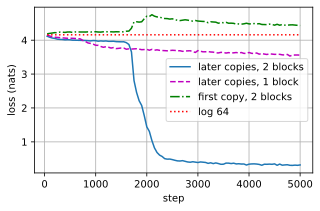

In [8]:
steps = list(range(50, 5001, 50))
d2l.plot(steps, [[h[1] for h in hist_two], [h[1] for h in hist_one],
                 [h[0] for h in hist_two], [math.log(64)] * len(steps)],
         'step', 'loss (nats)',
         legend=['later copies, 2 blocks', 'later copies, 1 block',
                 'first copy, 2 blocks', 'log 64'], figsize=(5, 3))

<!-- d2l:prose id=what-attention-computes-md-8 fw=all -->

## Evidence for the Circuit

To verify whether `model_two` actually implements the two-step induction
circuit of the figure, we inspect (1) its attention maps,
(2) its OV copy matrices, and (3) head ablations.

### Attention Patterns of the Learned Heads

On a test sequence of period $L = 24$, our circuit predicts that at least one
block-1 head should attend one position back ($j = i - 1$), and block-2 heads
should attend to the induction target $j = i + 1 - L = i - 23$ once $i \ge
24$:

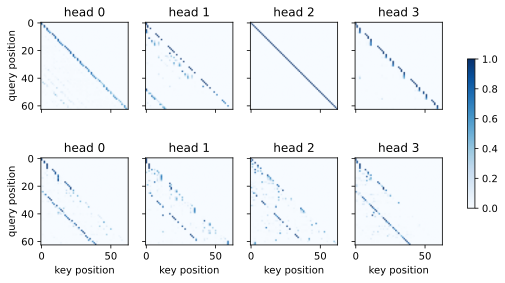

In [9]:
x, L = repeated_batch(1, 64, 64, 24, 24, d2l.try_gpu())
with torch.inference_mode():
    maps = torch.stack(model_two.attention_weights(x[:, :-1]))
d2l.show_heatmaps(maps[:, 0], xlabel='key position',
                  ylabel='query position',
                  titles=[f'head {h}' for h in range(4)],
                  figsize=(9, 4.5), cmap='Blues')

<!-- d2l:prose id=what-attention-computes-md-9 fw=all -->

To quantify both roles across variable pattern lengths $L \in \{16, \ldots,
32\}$ and across all three runs, `head_scores` computes each head's mean
attention weight on the previous token ($j = i - 1$) and on the induction
target ($j = i + 1 - L$ for $i \ge L$):

In [10]:
@torch.inference_mode()
def head_scores(model, x, L):
    """Mean attention on the previous token and on the induction target:
    shape (blocks, 2, heads)."""
    maps = torch.stack(model.attention_weights(x[:, :-1]))
    i = torch.arange(maps.shape[-1], device=x.device)
    tgt = i + 1 - L[:, None]               # Induction target of query i
    is_tgt = i == tgt[..., None]           # (batch, query, key)
    valid = tgt >= 1                       # Query token occurred before
    prev = maps.diagonal(-1, dim1=3, dim2=4).mean((1, 3))
    ind = (maps * is_tgt[:, None]).sum(-1)  # (blocks, batch, heads, query)
    ind = (ind * valid[:, None]).sum((1, 3)) / valid.sum()
    return torch.stack((prev, ind), 1)

x, L = repeated_batch(256, 64, 64, 16, 32, d2l.try_gpu())
all_scores = [head_scores(model, x, L) for model in models_two]
scores = all_scores[0]  # Run 1, whose maps are shown above
for r, run_scores in enumerate(all_scores):
    for b, rows in enumerate(run_scores.tolist()):
        for name, row in zip(('previous', 'induction'), rows):
            print(f'run {r + 1}, block {b + 1}, {name:<9}: '
                  + ' '.join(f'{v:.2f}' for v in row))

run 1, block 1, previous : 0.34 0.46 0.00 0.50
run 1, block 1, induction: 0.00 0.01 0.00 0.00
run 1, block 2, previous : 0.09 0.12 0.07 0.14
run 1, block 2, induction: 0.40 0.38 0.41 0.58
run 2, block 1, previous : 0.02 0.03 0.99 0.00
run 2, block 1, induction: 0.00 0.01 0.00 0.00
run 2, block 2, previous : 0.07 0.06 0.08 0.06
run 2, block 2, induction: 0.45 0.58 0.23 0.61
run 3, block 1, previous : 0.19 0.01 0.39 0.46
run 3, block 1, induction: 0.00 0.00 0.00 0.00
run 3, block 2, previous : 0.08 0.07 0.06 0.07
run 3, block 2, induction: 0.20 0.20 0.47 0.24


<!-- d2l:prose id=what-attention-computes-md-10 fw=all -->

In every run, between one and three block-1 heads specialize as previous-token heads,
while block-2 heads concentrate attention on the induction target $j = i + 1
- L$.

### The Copy Matrix

Attending to position $j$ predicts $x_j$ only if block 2's OV circuit boosts
the logit of token $x_j$. Let

$$
C_{ab} = \mathbf{e}_b^\top \mathbf{W}_{\mathrm{OV}}\, \bar{\mathbf{h}}_a
$$

denote the logit boost assigned to token $b$ when the summed OV circuit of a
block reads the mean residual-stream vector $\bar{\mathbf{h}}_a$ at positions
holding token $a$ (or the raw embedding $\mathbf{e}_a$). A copying OV circuit
has its row maximum on the diagonal ($b = a$) across nearly all $64$ rows
(versus $1/64 \approx 0.02$ by chance):

In [11]:
def circuits(model, blk):
    """W_QK and W_OV of every head of block blk, each (heads, D, D)."""
    # nn.Linear stores its weight as (output, input), the orientation of the
    # column-vector equations, so no transpose is needed
    W_qkv = model.blks[blk]['qkv'].weight           # (3D, D): W_q; W_k; W_v
    W_o = model.blks[blk]['proj'].weight            # (D, D): heads in columns
    H, D = model.num_heads, W_o.shape[0]
    W_q, W_k, W_v = W_qkv.reshape(3, H, D // H, D)  # Each (H, d_h, D)
    W_QK = W_q.mT @ W_k
    W_OV = W_o.reshape(D, H, D // H).transpose(0, 1) @ W_v
    return W_QK, W_OV

@torch.inference_mode()
def copy_matrix(model, blk, X=None):
    """C[a, b] = e_b^T W_OV h_a: W_OV summed over the heads of blk, h_a the
    mean stream vector entering blk at the positions of token a in X, or the
    embedding e_a if X is None."""
    E = h = model.token_emb.weight
    if X is not None:
        S = model.stream(X, blk)[0]            # The stream entering blk
        h = torch.zeros_like(E).index_add_(0, X.flatten(), S.flatten(0, 1))
        h = h / torch.bincount(X.flatten(), minlength=len(E))[:, None]
    W_OV = circuits(model, blk)[1].sum(0)
    return h @ W_OV.T @ E.T

def diagonal_share(C):
    """Fraction of the rows of C whose largest entry is on the diagonal."""
    rows = torch.arange(len(C), device=C.device)
    return float((C.argmax(-1) == rows).float().mean())

<!-- d2l:prose id=what-attention-computes-md-11 fw=all -->

Evaluating `diagonal_share(copy_matrix(...))` across all three two-block training runs (both on the mean block-1 residual stream $\bar{\mathbf{h}}_a$ and on raw token embeddings $\mathbf{e}_a$) as well as on the one-block control model shows that the OV circuit forms a near-diagonal copying matrix:

rows whose largest entry is the diagonal (chance 1/64)
                                   run 1   run 2   run 3
2 blocks, block 2, mean stream      1.00    1.00    0.91
2 blocks, block 2, embeddings       0.61    0.97    0.70
1 block, mean stream                1.00


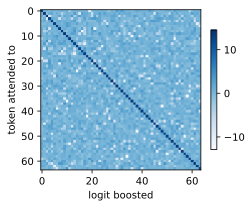

In [12]:
x, L = repeated_batch(256, 64, 64, 16, 32, d2l.try_gpu())
print('rows whose largest entry is the diagonal (chance 1/64)')
print(f'{"":<32}   run 1   run 2   run 3')
for name, X in (('2 blocks, block 2, mean stream', x),
                ('2 blocks, block 2, embeddings', None)):
    shares = [diagonal_share(copy_matrix(m, 1, X)) for m in models_two]
    print(f'{name:<32}' + ''.join(f'{v:8.2f}' for v in shares))
print(f'{"1 block, mean stream":<32}'
      f'{diagonal_share(copy_matrix(model_one, 0, x)):8.2f}')
d2l.show_heatmaps(copy_matrix(model_two, 1, x)[None, None].cpu(),
                  xlabel='logit boosted', ylabel='token attended to',
                  figsize=(3.6, 3.6), cmap='Blues')

<!-- d2l:prose id=what-attention-computes-md-12 fw=all -->

Notice two instructive subtleties: (1) the one-block control *also* learns a
diagonal OV copy matrix, showing that OV copying without QK K-composition
does not retrieve in-context successors (see Exercise
6); and (2) block 2 copies
more reliably from the block-1 stream $\bar{\mathbf{h}}_a$ than from raw
embeddings $\mathbf{e}_a$ alone, where the diagonal share varies widely from
run to run.

### Head Ablation

To test causal necessity, `ablate` zeroes out the output-projection slice
$\mathbf{W}_o^m$ of selected heads in a block. We compare removing block 1's
previous-token heads (score $> 0.2$), removing block 1's remaining heads, and
cumulatively removing block 2's induction heads from strongest to weakest:

In [13]:
def ablate(model, blk, heads):
    """Copy of model with the given heads of block blk removed."""
    model = copy.deepcopy(model)
    W_o = model.blks[blk]['proj'].weight   # (D, D): heads side by side
    with torch.no_grad():
        W_o.view(W_o.shape[0], model.num_heads, -1)[:, heads] = 0
    return model

<!-- d2l:prose id=what-attention-computes-md-13 fw=all -->

Applying `ablate` across all three trained two-block models quantifies how much later-copy cross-entropy and copy accuracy degrade when we remove block 1's previous-token heads versus block 2's top induction heads:

In [14]:
x, L = repeated_batch(256, 64, 64, 16, 32, d2l.try_gpu())
H, table = model_two.num_heads, {}  # Variant: (loss, accuracy) per run
for r, (model, s) in enumerate(zip(models_two, all_scores)):
    prev = [h for h in range(H) if s[0, 0, h] > 0.2]  # Previous-token heads
    rest = [h for h in range(H) if h not in prev]
    order = s[1, 1].argsort(descending=True).tolist()  # Strongest first
    print(f'run {r + 1}: block 1 previous-token heads {prev}, others {rest}')
    variants = {'none': model,
                'block 1, previous-token heads': ablate(model, 0, prev),
                'block 1, all other heads': ablate(model, 0, rest)}
    for k in range(1, H + 1):
        variants[f'block 2, top {k} induction'] = ablate(model, 1, order[:k])
    for name, variant in variants.items():
        table.setdefault(name, []).append(eval_copy(variant, x, L)[1:])
table['one-block model'] = [eval_copy(model_one, x, L)[1:]]
print(f'{"heads removed":<31}later-copy loss / accuracy: run 1, 2, 3')
for name, cols in table.items():
    print(f'{name:<31}'
          + ''.join(f'{rep:7.2f} /{acc:5.2f}' for rep, acc in cols))

run 1: block 1 previous-token heads [0, 1, 3], others [2]


run 2: block 1 previous-token heads [2], others [0, 1, 3]
run 3: block 1 previous-token heads [2, 3], others [0, 1]
heads removed                  later-copy loss / accuracy: run 1, 2, 3
none                              0.31 / 0.94   0.15 / 0.96   0.17 / 0.96
block 1, previous-token heads     4.64 / 0.07   3.71 / 0.09   3.80 / 0.17
block 1, all other heads          5.66 / 0.02   3.96 / 0.10   3.85 / 0.13
block 2, top 1 induction          0.63 / 0.92   0.56 / 0.91   1.65 / 0.70
block 2, top 2 induction          1.66 / 0.68   4.49 / 0.28   3.14 / 0.45
block 2, top 3 induction          3.38 / 0.24   5.68 / 0.06   3.88 / 0.23
block 2, top 4 induction          4.25 / 0.02   4.19 / 0.01   4.18 / 0.02
one-block model                   3.56 / 0.11


<!-- d2l:prose id=what-attention-computes-md-14 fw=all -->

Ablating block 1's previous-token heads collapses later-copy accuracy to
less than $0.2$, the level of the one-block model, confirming their necessity. Interestingly, ablating block 1's
*other* heads also breaks retrieval: because `copy_matrix` relied on block 1's
transformed stream (and zero-ablation shifts stream norms in an unnormalized
network; see Exercise 5 on
mean ablation), block 2 depends on those heads as well. In block 2, the four
heads share the induction workload redundantly, requiring multiple heads to
be ablated before accuracy drops to chance.

## In-Context Learning

### Generalization to Unseen Patterns

Because $64^{16} \approx 8 \times 10^{28}$ possible patterns exist, every test
sequence is novel and all token pairs are equally likely across the training
distribution. The induction circuit binds each token to its successor on the
fly from a single exposure in the context window—a minimal instance of
*in-context learning*:

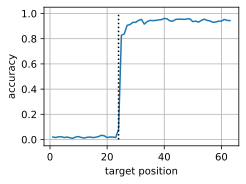

In [15]:
x, L = repeated_batch(512, 64, 64, 24, 24, d2l.try_gpu())
with torch.inference_mode():
    acc = (model_two(x[:, :-1]).argmax(-1) == x[:, 1:]).float().mean(0)
d2l.plot([torch.arange(1, 64), [24, 24]], [acc.cpu(), [0, 1]],
         'target position', 'accuracy', fmts=('-', 'k:'))

<!-- d2l:prose id=what-attention-computes-md-15 fw=all -->

Accuracy jumps from $1/64$ on the first copy (and at the restart boundary
$t = 24$, where content matching has not yet seen a repeated token) to
more than $0.9$ from position $25$ onward.

What accounts for the remaining error after the restart? When a
token appears $K > 1$ times within the $L$-token pattern with different
successors, matching on the current token alone is ambiguous: choosing
uniformly among the $K$ occurrences succeeds with probability $1/K$. For
$L = 24$ and $p = 1/64$, a token repeats in the pattern with probability
$1 - (63/64)^{23} \approx 0.30$, and uniform single-token matching predicts
an overall accuracy of

$$
\mathbb{E}\left[\frac{1}{K}\right] = \frac{1 - (1 - p)^L}{L p} \approx 0.84, \qquad p = \frac{1}{64},
$$

and $\approx 0.47$ on repeated tokens alone. Splitting test positions by
$K = 1$ (unique) versus $K > 1$ (repeated) shows that the three runs reach
$0.97$ or more on unique tokens and roughly $0.7$--$0.9$ on repeated tokens, well
above the $0.47$ single-token baseline. A plausible reason, which we do not
test here, is that the model also matches longer $n$-gram context and prefers
certain RoPE offsets (Exercise 2):

In [16]:
period, num_steps = 24, 64
x, _ = repeated_batch(512, num_steps, 64, period, period, d2l.try_gpu())
pattern = x[:, :period]
K = (pattern[:, :, None] == pattern[:, None, :]).sum(-1)  # Count in pattern
K = K[:, torch.arange(period, num_steps - 1) % period]  # Current token
parts = (K == 1, K > 1, K > 0)           # Unique, repeated, all
rows = {'share of targets': [p.float().mean() for p in parts],
        'single-token match': [(1 / K[p]).mean() for p in parts]}
for r, model in enumerate(models_two):
    with torch.inference_mode():
        hit = (model(x[:, :-1]).argmax(-1) == x[:, 1:])[:, period:]
    rows[f'run {r + 1} accuracy'] = [hit[p].float().mean() for p in parts]
print(f'{"current token":<18}   unique repeated      all')
for name, row in rows.items():
    print(f'{name:<18}' + ''.join(f'{v:9.2f}' for v in row))

current token        unique repeated      all
share of targets       0.69     0.31     1.00
single-token match     1.00     0.47     0.84
run 1 accuracy         0.99     0.80     0.93
run 2 accuracy         1.00     0.87     0.96
run 3 accuracy         1.00     0.85     0.95


<!-- d2l:prose id=what-attention-computes-md-16 fw=all -->

### Induction Heads in Larger Models

@Olsson.Elhage.Nanda.ea.2022 demonstrated that induction heads form
during an abrupt phase transition in language models across scales, coinciding
with the emergence of general in-context learning (Exercise
8). Beyond copying and fuzzy pattern
completion, attention layers can also implement in-context gradient steps on
regression tasks (Exercise
7,
[@Oswald.Niklasson.Randazzo.ea.2023]), although whether pretrained
language models learn in context this way is disputed
[@Shen.Mishra.Khashabi.2024].

Our analysis leaned on a model with no normalization and no MLP, and a real
transformer block (that section) has both. Each changes the
method without changing the idea. Layer normalization rescales the stream by
its own norm, so the map from stream to logits is linear only once that scale
is held fixed; circuit analyses freeze it at its observed value and treat the
rest as before. MLPs add paths that pass through no attention pattern, and a
head's output may be rewritten by an MLP before a later head reads it. Finally,
induction heads in trained language models match fuzzily: they complete
$[\mathrm{A}^*][\mathrm{B}^*] \ldots [\mathrm{A}] \to [\mathrm{B}]$ for tokens
that are merely similar, not identical, to the ones seen earlier.

## Attention Weights as Explanations

Our investigation illustrates why attention heatmaps alone are insufficient as
mechanistic explanations:

* **Important heads can have unremarkable maps:** Block 1's non-previous-token
  heads looked inert in the heatmaps, yet ablating them broke block 2's
  retrieval.
* **Sharp maps can have negligible effect:** In pretrained language models,
  idle heads frequently place most of their weight on the first token (an
  *attention sink*), whose OV vector has near-zero norm
  [@Xiao.Tian.Chen.ea.2024; @Gu.Pang.Du.ea.2025].

the table summarizes the hierarchy of evidence used to
validate the induction circuit.

<!-- tbl-caption:Evidence for the induction-head interpretation, by level. -->

| check in this section | evidence level | supported conclusion | remaining limitation |
|:--|:--|:--|:--|
| later-copy loss | behavioral | two blocks solve the repeated-token task, one does not | identifies no component |
| period change | input intervention | the fixed-period model uses position, not content | changes the task as well as the input |
| head scores | activation | heads attend with the predicted offsets | omits the value transformation |
| copy matrix | weights and mean activations | block 2's OV circuits copy tokens | also present in a model that does not retrieve |
| head ablation | component intervention | later-copy prediction needs all of block 1, not only its previous-token heads, and block 2's induction heads | zeroing moves the stream off its training distribution |

## Summary

Each attention head acts on the residual stream through two matrices of rank at most $d_h$: a **QK circuit** $\mathbf{W}_q^\top \mathbf{W}_k$ governing where it attends and an **OV circuit** $\mathbf{W}_o \mathbf{W}_v$ governing what vector it writes to the destination position. A single attention layer can represent bigrams and skip-trigrams (including single-token copying), whereas completing novel in-context patterns $[\mathrm{A}][\mathrm{B}] \ldots [\mathrm{A}] \to [\mathrm{B}]$ requires at least two layers so that a **previous-token head** and a match-and-copy **induction head** can compose through the residual stream. Trained on repeated random patterns of variable period, a two-block model undergoes a sharp phase transition to more than $90\%$ in-context accuracy, whereas a fixed period allows a one-block model to exploit a brittle positional shortcut. Establishing what a head computes in practice therefore requires combining attention-pattern probes, OV weight inspection, and causal head ablations.

## Exercises

1. **Tied bigrams.** With zero blocks, the logit of token $b$ after token
   $a$ is $\mathbf{e}_b^\top \mathbf{e}_a$, so the geometry of the
   embeddings alone fixes which successor the model prefers. Call $b$ the
   *top successor* of $a$ when $\mathbf{e}_b^\top \mathbf{e}_a$ is the
   largest logit of that row, and assume that there are no ties.
    1. Show that if all embeddings have the same norm, the top successor of
       every token is the token itself.
    1. Drop the equal-norm assumption. Show that a token $b \neq a$ can be
       the top successor of $a$ only if $\|\mathbf{e}_b\| >
       \|\mathbf{e}_a\|$, and conclude that the top successors cannot form a
       cycle $a_1 \to a_2 \to \cdots \to a_k \to a_1$ with $k \geq 2$.
    1. Suppose that in a corpus the most frequent successor of the
       character `t` is `h`, that of `h` is `e`, that of `e` is the space,
       and that of the space is `t`. Show that no zero-block model
       reproduces all four as top successors, however long it is trained.
    1. In a one-block model, every head at the first position attends only
       to that position. Write the logits there as $\mathbf{E}\mathbf{M}
       \mathbf{e}_{x_0}$ for a matrix $\mathbf{M}$ built from the OV
       circuits, and explain why neither constraint of the previous parts
       applies to $\mathbf{E}\mathbf{M}\mathbf{E}^\top$.

1. **Paths through two blocks.** Fix the attention patterns of a model with
   $N$ blocks of $H$ heads on a sequence of $T$ tokens, and write
   $\mathbf{A}^{\ell m}$ for the $T \times T$ matrix with entries
   $\alpha_{ij}^{\ell m}$.
    1. Expand the logits of the equation for $N = 2$ into a
       sum of path terms. Show that the path through head $m$ of block 1 and
       head $m'$ of block 2 acts like a single head with pattern
       $\mathbf{A}^{2m'}\mathbf{A}^{1m}$ and OV circuit
       $\mathbf{W}_{\mathrm{OV}}^{2m'}\mathbf{W}_{\mathrm{OV}}^{1m}$, and
       bound the rank of that circuit.
    1. Count the path terms for $N$ blocks, and evaluate the count for
       `model_two`.
    1. In a trained model the patterns of block 2 are not fixed: they depend
       on $\mathbf{h}^{(1)}$ through the QK circuit of block 2. Substitute
       $\mathbf{h}_i^{(1)}$ and $\mathbf{h}_j^{(1)}$ into the score of
       the equation and sort the terms by whether the query side, the
       key side, or both contain the output of a block-1 head. These terms
       are called *Q-composition* and *K-composition*, and the path of the
       first part is *V-composition* [@Elhage.Nanda.Olsson.ea.2021].
       Which kind of term does the induction circuit of
       the figure rely on?
    1. Show that two blocks can match on the two-token prefix
       $(x_{i-1}, x_i)$ when block 1 contains heads that attend to offsets
       $-1$ and $-2$, and name the composition term that carries each half
       of the match.

1. [code] **The shortcut without biases.** The fixed-offset model of
   that section has projection biases.
    1. Let a head's query and key before rotation be the same constant
       vectors $\mathbf{q}$ and $\mathbf{k}$ at every position. Show with
       $\mathbf{R}_i^\top \mathbf{R}_j = \mathbf{R}_{j-i}$ that the score
       depends only on the offset $j - i$, and explain how $\mathbf{q}$ and $\mathbf{k}$ can be chosen
       so that the score is largest at offset $-31$.
    1. Without biases, every query and key is a linear function of the
       stream. What must the token embeddings contain for a head to produce
       nearly constant queries and keys?
    1. Train the one-block model of the text with `bias=False` three times
       and report the second-copy accuracy and each head's attention at
       offset 31. How reliably does the shortcut form without biases, and
       does it survive the period-24 probe?

1. **Weights that change nothing.** The output of a head at query $i$ is
   $\mathbf{W}_{\mathrm{OV}} \sum_j \alpha_{ij}\, \mathbf{h}_j$ by
   the equation, and the softmax makes every weight
   $\alpha_{ij}$ on an unmasked key positive. @Jain.Wallace.2019
   found that in trained text classifiers quite different attention
   distributions often leave the prediction unchanged, and concluded that
   attention weights do not explain predictions.
    1. Show that the attention distributions over $n$ keys that give the
       same head output as $\boldsymbol{\alpha}_i$ contain, around
       $\boldsymbol{\alpha}_i$, a piece of an affine subspace of dimension
       at least $n - 1 - d_h$. Evaluate the bound for the last query of a
       63-token input to `model_two`.
    1. The alternatives of the first part are constructed for one input at
       a time, as are those of @Jain.Wallace.2019 .
       @Wiegreffe.Pinter.2019 argued that an alternative counts
       against an explanation only if a single trained model produces such
       alternatives on every input while making nearly the same
       predictions. Explain why the dimension count of the first part says
       nothing about whether such a model exists, and describe an
       experiment that would decide it for `model_two`.

1. [code] **Zero and mean ablation.** The ablations of
   that section set a head's output to zero.
    1. Explain why zeroing a head's columns of `proj` removes exactly that
       head's contribution to the residual stream. When a block-1 head is
       removed, which attention patterns stay unchanged and which can
       change?
    1. A head's output is never zero in training, so zeroing moves the
       stream to states the model has not seen. *Mean ablation* replaces
       the output $\mathbf{o}_m$ of head $m$ by its average
       $\bar{\mathbf{o}}_m$ over positions and sequences instead. Implement
       it: build a `TinyCharLM` with `bias=True`, copy the weights of
       `model_two` into it with zero `qkv` biases, zero head $m$'s columns
       of `proj`, and set the bias of `proj` to the product of these
       columns, before zeroing, with $\bar{\mathbf{o}}_m$. Repeat the
       ablations of the text. Does removing the heads of block 1 that are
       not previous-token heads still break retrieval, and which of the
       two readings of that section does the answer
       support?
    1. Remove the second-strongest induction head of block 2 on its own.
       Compare the sum of the two single-head increases in later-copy loss
       with the increase when both heads are removed together. What does
       the comparison say about how the heads share the work?
    1. Which limitations in the table does mean
       ablation remove, and which remain?

1. [code] **K-composition in the weights.** ● The match of the induction
   head works because the QK circuit of block 2 reads what the OV circuit
   of block 1 wrote into the stream.
    1. For every pair of head $m$ of block 1 and head $m'$ of block 2 of
       `model_two`, compute the $64 \times 64$ matrix
       $$\mathbf{E}\, \mathbf{W}_{\mathrm{QK}}^{2m'}\, \mathbf{W}_{\mathrm{OV}}^{1m}\, \mathbf{E}^\top,$$
       whose entry $(a, b)$ scores a query token $a$ against a key whose
       predecessor was $b$. Measure the fraction of rows whose largest
       entry lies on the diagonal, as the copy test of
       the equation does for copying.
    1. Compare with the direct path $\mathbf{E}\,
       \mathbf{W}_{\mathrm{QK}}^{2m'}\, \mathbf{E}^\top$ of the same block-2
       heads. Which pairs of heads carry the match, and do they agree with
       the attention-based scores of `head_scores`?
    1. The computation ignores the rotation that RoPE applies inside the QK
       circuit. Include the relative rotation $\mathbf{R}_{j-i}$ for a
       fixed offset, and check whether doing so at offset $-23$ changes
       the ranking of the pairs.

1. [code] **A head that takes a gradient step.** ● Induction heads learn
   from the context by copying. A model can also infer a rule from labeled
   examples in its context. Let a sequence hold pairs $(\mathbf{x}_i,
   y_i)$, $i = 1, \ldots, n$, with standard normal $\mathbf{x}_i \in
   \mathbb{R}^p$ and $y_i = \mathbf{w}^\top \mathbf{x}_i$ for a vector
   $\mathbf{w}$ drawn afresh for every sequence, followed by a query
   $\mathbf{x}_q$ whose label is to be predicted.
    1. Show that one step of gradient descent on $\frac{1}{2}\sum_i (y_i -
       \mathbf{w}^\top \mathbf{x}_i)^2$, started at $\mathbf{w} =
       \mathbf{0}$ with learning rate $\eta$, predicts $\hat{y}_q = \eta
       \sum_i y_i\, \mathbf{x}_i^\top \mathbf{x}_q$. Read this as
       attention without a softmax: what plays the query, the keys, and the
       values? Compare it with the linear attention of
       that section with feature map
       $\phi(\mathbf{x}) = \mathbf{x}$.
    1. Give each example the token $\mathbf{z}_i = [\mathbf{x}_i; y_i] \in
       \mathbb{R}^{p+1}$ and the query the token $\mathbf{z}_q =
       [\mathbf{x}_q; 0]$. Choose the query, key, and value maps of one
       head without a softmax so that its output at the query token is
       $\hat{y}_q$. Why does it not matter that the query token also
       attends to itself? Implement the head and check it against the
       gradient step. Do the head's weights depend on $\mathbf{w}$?
    1. With $\eta = 1/n$, show that the step gives $\mathbf{w}_1 =
       \big(\frac{1}{n}\sum_i \mathbf{x}_i \mathbf{x}_i^\top\big)
       \mathbf{w}$ and that $\mathbb{E}\,\|\mathbf{w}_1 - \mathbf{w}\|^2 =
       \frac{p+1}{n}\|\mathbf{w}\|^2$. Hint: for a standard normal
       $\mathbf{x}$, $\mathbb{E}[(\mathbf{x}^\top \mathbf{w})^2
       \|\mathbf{x}\|^2] = (p+2)\|\mathbf{w}\|^2$. Conclude that the
       expected squared error of $\hat{y}_q$, relative to the variance of
       $y_q$, is $(p+1)/n$.
    1. For $p = 8$, measure the relative error over 500 sequences at $n =
       10$, 100, and 1000 and compare it with the prediction $9/n$. At $n =
       10$, how does the head compare with always predicting zero?

1. [extended] **Induction heads in text.** ●●
   @Olsson.Elhage.Nanda.ea.2022 tie the formation of induction
   heads in language models to an abrupt gain in in-context learning,
   measured as the drop in loss from early to late positions of the
   context. Test this on the byte-level model
   of that section.
    1. Train `d2l.TinyCharLM` with `pos='rope'` on the WikiText-103 bytes
       of that section in 30 rounds of 100 steps of
       `d2l.train_steps`. After each round, record two quantities. The
       first is the largest induction-target score of a block-2 head on
       repeated random sequences over the text vocabulary with pattern
       lengths 16 to 32, computed with `head_scores`. The second is the
       in-context gain, the validation loss at target positions 0 to 15
       minus that at positions 96 to 127.
    1. Plot both quantities against the training step. Do the induction
       score and the in-context gain rise in the same window?
    1. After training, remove the block-2 heads with the highest induction
       scores with `ablate`, and measure the in-context gain and the
       validation loss again. How much of the gain do these heads carry?
    1. The repeated random sequences contain no structure besides
       repetition, while text repeats words and phrases at irregular
       distances. Which of your results would change if the text contained
       no repeated words, and why?

[Discussions](https://d2l.discourse.group/t/36773)